**SVD, classical PCA, probabilistic PCA, and LSA**
- 

**Libraries**
-

In [76]:
from pathlib import Path
import sys
from IPython.display import display

# Locate the project package from the project or notebooks folder.
project_root = Path.cwd().resolve()
if project_root.name == "notebooks":
    project_root = project_root.parent
if not (project_root / "src" / "__init__.py").is_file():
    raise RuntimeError("Start Jupyter from the project root or notebooks folder.")
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from src.models.dimensionality_reduction import (
    ReductionData, SVDSearch, PCASearch, PPCASearch,
    SVDAnalysis, PCAAnalysis, PPCAAnalysis, ReductionComparison,
)
from src.models.dimensionality_reduction_plots import plot_search, plot_loadings


## **1. Question of Interest**

### **1.1 Question**


- How much the order patterns can be represented with a reduced number of latent factors withouth losing substantial information of their variability? 

### **1.2 Objectives and Assumptions per Model**

| Aspect | Truncated SVD | Classical PCA | Probabilistic PCA (PPCA) |
|---|---|---|---|
| **Main objective** | Find a low-rank approximation of the original data matrix. | Find orthogonal directions that maximize explained variance. | Model the observed data using a lower-dimensional probabilistic latent representation. |
| **Optimization objective** | Minimize rank-$k$ reconstruction error in Frobenius norm. | Maximize retained variance, equivalently minimize centered reconstruction error. | Maximize the likelihood of the observed data under a Gaussian latent-variable model. |
| **Data centering** | Not required. Can operate directly on uncentered data. | Required to identify directions of maximum variance around the mean. | The mean is explicitly modeled; data can be centered during estimation. |
| **Linear relationship** | Assumes the data can be approximated by a low-rank linear structure. | Assumes a linear projection captures the relevant variation. | Assumes observations are generated through a linear transformation of latent variables plus noise. |
| **Latent variables** | Deterministic representations obtained from the SVD. | Deterministic principal component scores. | Unobserved random variables following a standard Gaussian distribution. |
| **Noise assumption** | No explicit probabilistic noise assumption. | No explicit probabilistic noise assumption. | Independent, isotropic Gaussian noise with covariance $\sigma^2I_p$. |
| **Distributional assumptions** | None required. | None required. | Gaussian latent variables and Gaussian noise, implying Gaussian observations. |
| **Orthogonality** | Singular vectors are orthonormal. | Principal directions are orthonormal. | The columns of $W$ are not required to be orthonormal. |
| **Covariance** | No covariance matrix is required. | Uses the empirical covariance $S$. | Estimates the model covariance $C=WW^\top+\sigma^2I_p$. |
| **Uncertainty modeling** | No explicit uncertainty model. | No explicit uncertainty model. | Provides probabilistic inference and uncertainty estimates for latent variables. |

## **2. Database Loading and Train/Validation/Test Split**

In [77]:
data = ReductionData()
data.frame.head()


,Type,Days for shipping (real),Days for shipment (scheduled),Benefit per order,Sales per customer,Delivery Status,Late_delivery_risk,Category Name,Customer City,Customer Country,Customer Id,Customer Segment,Customer State,Customer Zipcode,Department Name,Latitude,Longitude,Market,Order City,Order Country,Order Item Discount,Order Item Discount Rate,Order Item Profit Ratio,Order Item Quantity,Sales,Order Region,Order State,Order Status,Product Card Id,Product Name,Product Price,Shipping Mode,Order Month
0,DEBIT,3,4,91.250000,314.640015,Advance shipping,0,Sporting Goods,Caguas,Puerto Rico,20755,Consumer,PR,725.0,Fitness,18.251453,-66.037056,Pacific Asia,Bekasi,Indonesia,13.110000,0.04,0.29,1,327.75,Southeast Asia,Java Occidental,COMPLETE,1360,Smart watch,327.75,Standard Class,1
1,TRANSFER,5,4,-249.089996,311.359985,Late delivery,1,Sporting Goods,Caguas,Puerto Rico,19492,Consumer,PR,725.0,Fitness,18.279451,-66.037064,Pacific Asia,Bikaner,India,16.389999,0.05,-0.80,1,327.75,South Asia,Rajastán,PENDING,1360,Smart watch,327.75,Standard Class,1
2,CASH,4,4,-247.779999,309.720001,Shipping on time,0,Sporting Goods,San Jose,EE. UU.,19491,Consumer,CA,95125.0,Fitness,37.292233,-121.881279,Pacific Asia,Bikaner,India,18.030001,0.06,-0.80,1,327.75,South Asia,Rajastán,CLOSED,1360,Smart watch,327.75,Standard Class,1
3,DEBIT,3,4,22.860001,304.809998,Advance shipping,0,Sporting Goods,Los Angeles,EE. UU.,19490,Home Office,CA,90027.0,Fitness,34.125946,-118.291016,Pacific Asia,Townsville,Australia,22.940001,0.07,0.08,1,327.75,Oceania,Queensland,COMPLETE,1360,Smart watch,327.75,Standard Class,1
4,PAYMENT,2,4,134.210007,298.250000,Advance shipping,0,Sporting Goods,Caguas,Puerto Rico,19489,Corporate,PR,725.0,Fitness,18.253769,-66.037048,Pacific Asia,Townsville,Australia,29.500000,0.09,0.45,1,327.75,Oceania,Queensland,PENDING_PAYMENT,1360,Smart watch,327.75,Standard Class,1


In [78]:
data.features


['Days for shipping (real)',
 'Days for shipment (scheduled)',
 'Benefit per order',
 'Sales per customer',
 'Order Item Discount',
 'Order Item Discount Rate',
 'Order Item Profit Ratio',
 'Order Item Quantity',
 'Sales',
 'Product Price']

In [79]:
data.train.shape, data.validation.shape, data.test.shape


((126363, 10), (27078, 10), (27078, 10))

## **3. Singular Value Decomposition (SVD)**

### **3.1 Metrics and Notation**

Here we are going to use Singular Value Decomposition (SVD) that basically helps us to reduce de dimensionality of data by decomposing a matrix $X$ into three matrices $U,\Sigma$ and $V^T$ as follows:

$$
X = U\Sigma V^T
$$

where U ilustrate the data with orthogonal directions , $\Sigma$ is a matrix that has the singular values and shows the strenght of each component and $V^T$ indicates how the original variable support each component.

In this way, we are trying to find orthogonal directions that summer patterns in the original matrix, helping us to identify which components carry the most of the energy (which means the variability of the data). 

Therefore, we are goint to use Truncated SVD which uses SVD to retain the singular directions needed to reconstruct the matrix but only keeping the first k components.

$$
\boxed{
X\approx X_k=U_k\Sigma_kV_k^T
}
$$

The Eckart-Young-Mirsky Theorem tells us that Truncated SVD provides the best rank-k approximation when there are computed exactly the leading singular vectors, using the Frobenius Norm.
$$
\boxed{
X_k=
\underset{\operatorname{rank}(A)\leq k}{\arg\min}
\|X-A\|_F^2
}
$$

Finally, we can introduce latent components by using ahora approximated matrix $X_k$ by grouping $U_k$ and $\Sigma_k$ in $Z=U_k \Sigma_k$, obtaining that $X_k=ZV_k^T$. Z is the matrix that contains the coordinates of all the observations in the new k-dimensional space.


### **3.2 Scaling**

In [80]:
# Scaling is fitted on training data only; SVD does not center the features.
data.train_scaled.shape, data.validation_scaled.shape, data.test_scaled.shape

((126363, 10), (27078, 10), (27078, 10))

### **3.3 Applying SVD with different $k$**

In [81]:
svd_search = SVDSearch().run(data)
display(svd_search.results.round(4))


,k,Train MSE,Validation MSE,Train Relative Frobenius,Validation Relative Frobenius,Retained Energy,Subspace Stability,Stability SD,Mean Concentration,Silhouette Score
0,1,0.7973,0.8096,0.5141,0.5161,0.7358,1.0000,0.0000,0.1514,NaN
1,2,0.5449,0.5408,0.4249,0.4218,0.8194,0.9998,0.0002,0.1530,0.4529
2,3,0.3637,0.3627,0.3472,0.3454,0.8794,0.9999,0.0000,0.2615,0.4117
3,4,0.2158,0.2138,0.2675,0.2652,0.9285,0.9999,0.0001,0.2694,0.3445
4,5,0.0893,0.0875,0.1720,0.1697,0.9704,1.0000,0.0000,0.2938,0.2333
5,6,0.0407,0.0392,0.1161,0.1136,0.9865,1.0000,0.0000,0.3282,0.1845
6,7,0.0208,0.0189,0.0831,0.0789,0.9931,0.9987,0.0022,0.3305,0.1755
7,8,0.0041,0.0041,0.0369,0.0369,0.9986,1.0000,0.0000,0.3380,0.1666
8,9,0.0000,0.0000,0.0000,0.0000,1.0000,1.0000,0.0000,0.3391,0.1478


### **3.4 Metrics Visualization**

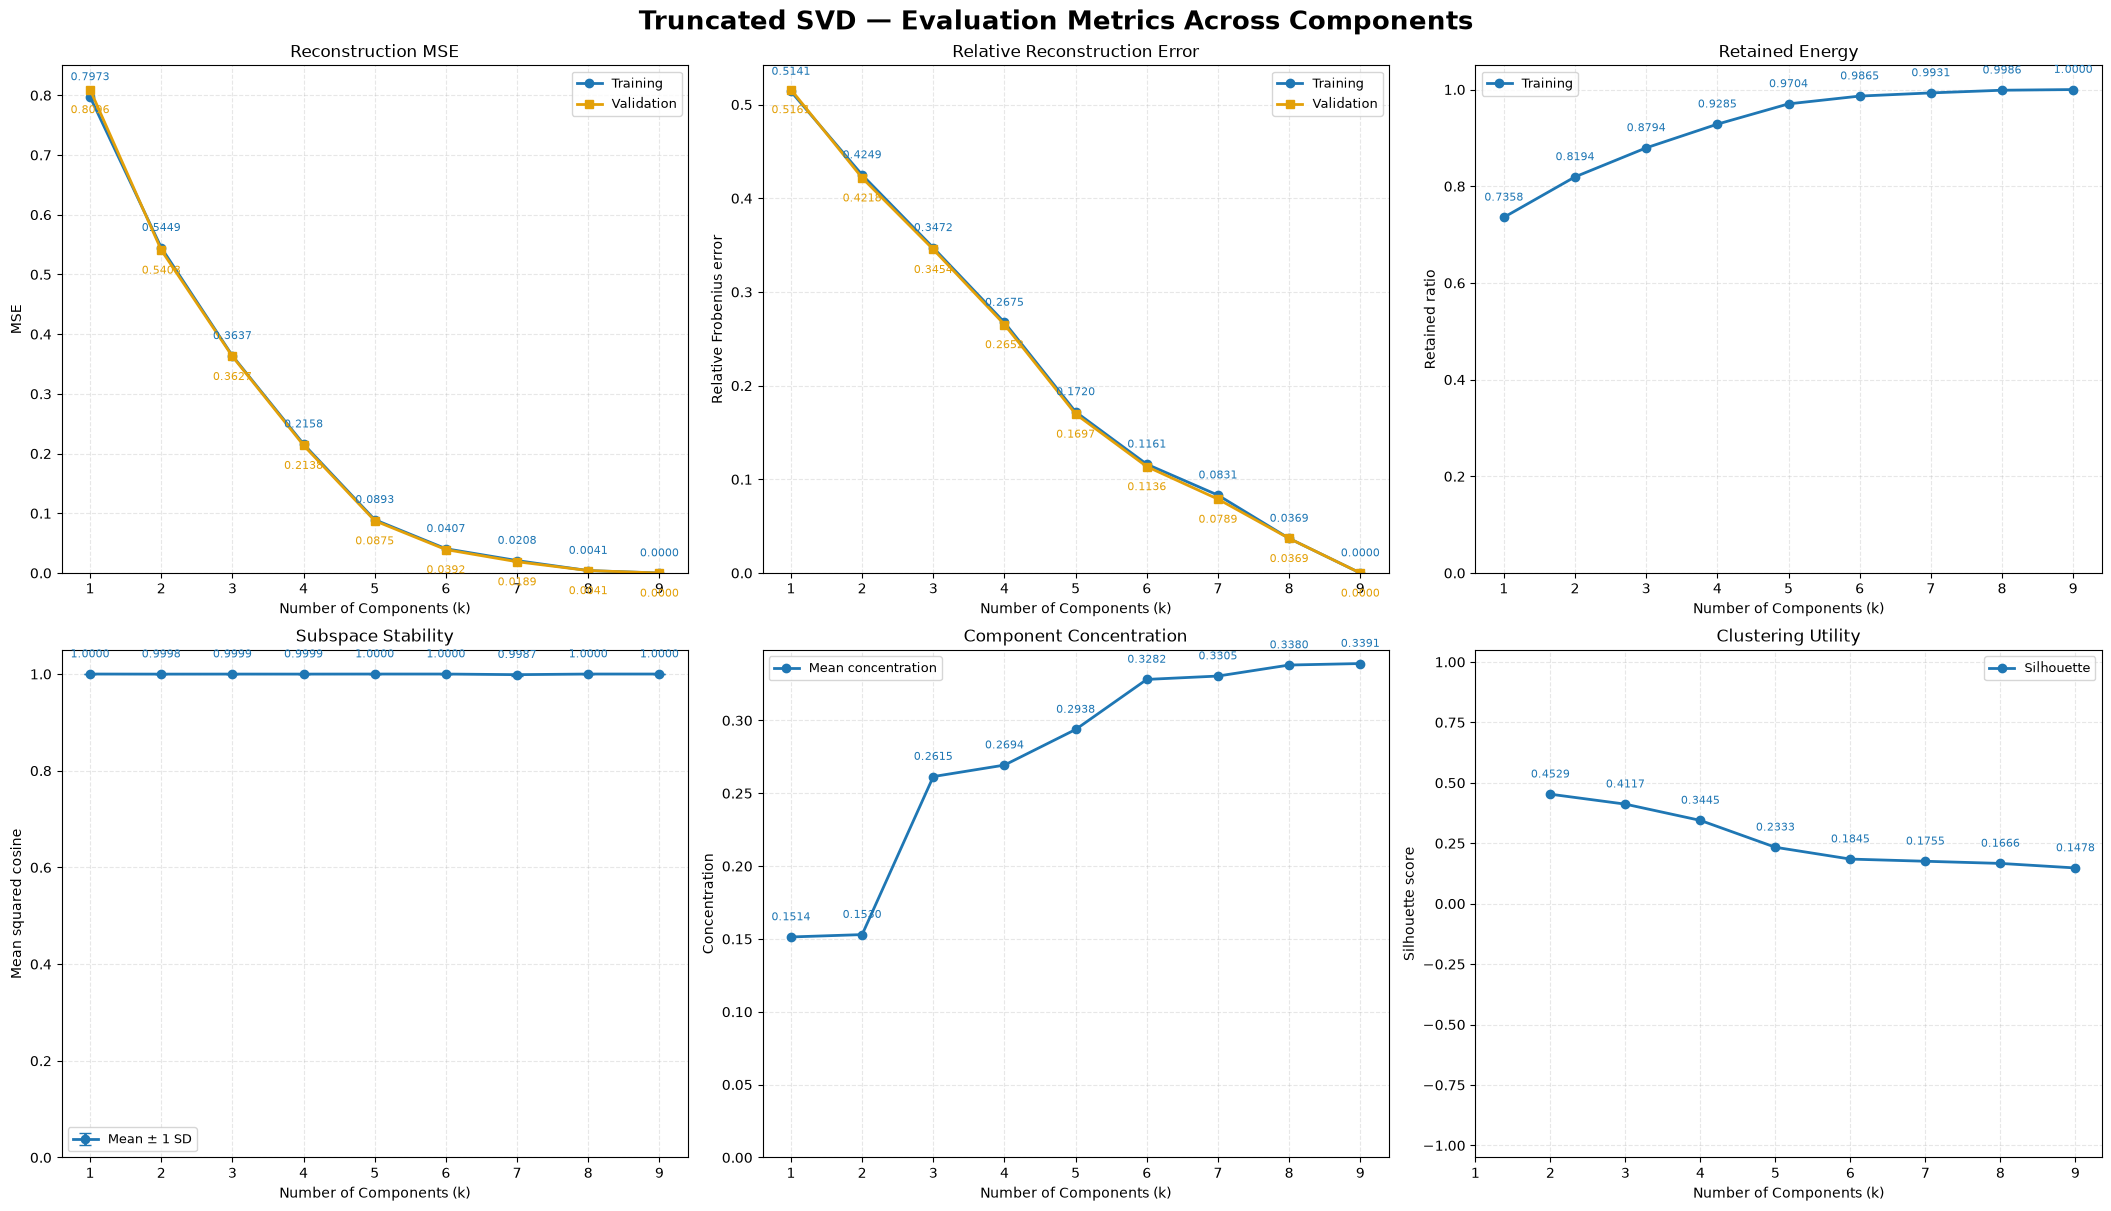

In [82]:
plot_search(svd_search)


**Observations**

From the previous graphics, we can see that $k=5$ is a reasonable because:
- The reconstruction error and relative reconstruccion error is moderate, it presents better values than lower number of components.
- With $k=5$ components the Retained Matrix Energy reaches 97% of the training matrix squared magnitude.
- The stable subspace appears extremely stable under boostrap resampling.
- It moderates the concentración of the coefficients of the components-
- It gives a reasonable value por cluster separation in constrast with higher numbers of components


### **3.5 SVD with $k=5$ Analysis**

In [83]:
svd_analysis = SVDAnalysis(data, k=5).fit()


In [84]:
svd_analysis.latent_frame("train").head()


,SVD_1,SVD_2,SVD_3,SVD_4,SVD_5
99963,4.706722,-1.619635,-3.950066,0.813189,0.184968
63538,4.333551,0.039334,-0.437158,-1.099856,-0.478415
6661,4.691826,-0.655246,0.519686,1.174649,0.202437
93913,5.042431,-1.017921,-0.446851,1.408136,-1.830423
90626,4.440120,-0.806127,-0.908433,0.892490,-1.367697


In [85]:
svd_analysis.model.components_


array([[ 0.46719734,  0.4632577 ,  0.05207326,  0.35464133,  0.23610291,
         0.31088221,  0.05579666,  0.30927302,  0.36090651,  0.23922363],
       [-0.39381457, -0.38850522,  0.09297617,  0.398223  ,  0.27705143,
        -0.08949884,  0.01872271, -0.25197964,  0.40722636,  0.46076299],
       [-0.00222902, -0.0015322 ,  0.69363464, -0.02699081, -0.09137203,
        -0.08416915,  0.704834  ,  0.03594244, -0.03957214, -0.05525473],
       [-0.26828819, -0.27254771,  0.03493927, -0.18640831,  0.4584106 ,
         0.69263667,  0.06319641,  0.25028048, -0.09364262, -0.22908842],
       [-0.20272722, -0.20400754, -0.03405592,  0.24500444, -0.14507433,
        -0.33408653, -0.06697398,  0.7768748 ,  0.19851131, -0.27569645]])

In [86]:
svd_analysis.loadings.round(4)


,SVD_1,SVD_2,SVD_3,SVD_4,SVD_5
Days for shipping (real),0.4672,-0.3938,-0.0022,-0.2683,-0.2027
Days for shipment (scheduled),0.4633,-0.3885,-0.0015,-0.2725,-0.2040
Benefit per order,0.0521,0.0930,0.6936,0.0349,-0.0341
Sales per customer,0.3546,0.3982,-0.0270,-0.1864,0.2450
Order Item Discount,0.2361,0.2771,-0.0914,0.4584,-0.1451
Order Item Discount Rate,0.3109,-0.0895,-0.0842,0.6926,-0.3341
Order Item Profit Ratio,0.0558,0.0187,0.7048,0.0632,-0.0670
Order Item Quantity,0.3093,-0.2520,0.0359,0.2503,0.7769
Sales,0.3609,0.4072,-0.0396,-0.0936,0.1985
Product Price,0.2392,0.4608,-0.0553,-0.2291,-0.2757


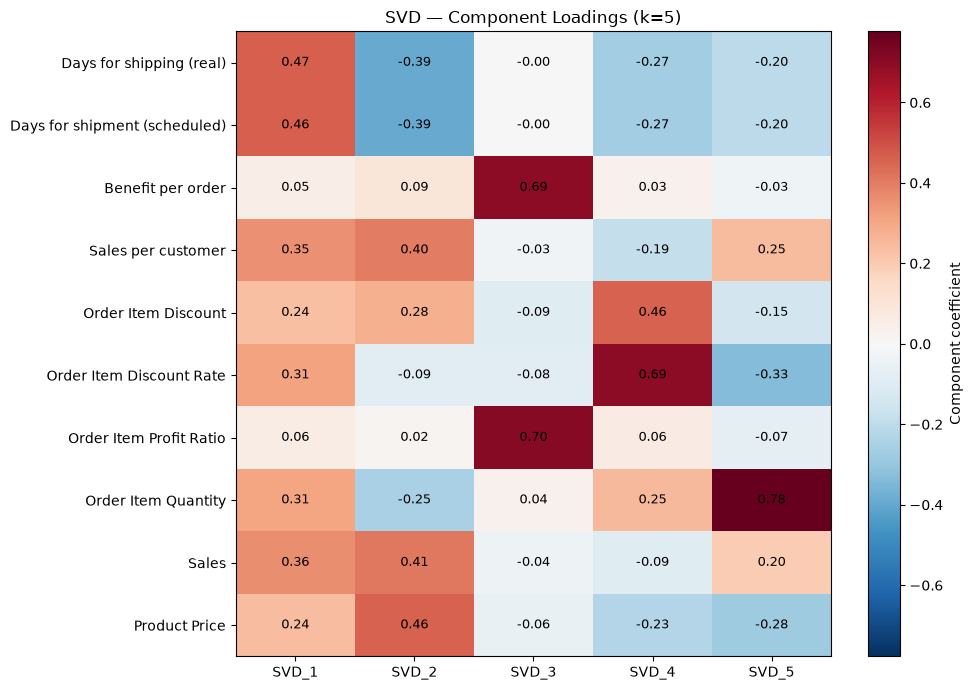

In [87]:
plot_loadings(svd_analysis)


**Observations**
- **Component 1 — Shipping Duration and Transactional Activity:** This component captures positive contributions with Days for shipping (real), Days of shipping (scheduled), Sales per customer, Order item Discount, Order item discount rate, Order item quantit, Sales and Product price. It appears to capture a general pattern of orders with long delivery time with higher transactional activity.

- **Component 2 — Transactional Value and Shipping Duration:** This component constrast positive contributions with Sales, Product price, Sales per customer and Order item discount with negative constributions with Days for shipping (real), Days for shipping (scheduled) and Order item quantity. This could suggest that the componentn captures orders that take less time to deliver and items, but with more transactional activity, higher prices and discounts.

- **Component 3 — Profitability:** This component is dominated by Benefit per Order and Order Item Profit Ratio, suggesting that it captures profitability-related variation with relatively little contribution from other variables.

- **Component 4 — Discounts and Shorter Shipping Duration:** This component involves positive contributions from Order item discount, Order item discount rate and Order item quantity, but negative contributions with Days for shipping (real), Days for shipping (scheduled), Product price and sales per customer. This componennt could capture the orders that are fastly delivered and have a high discount on their products.

- **Component 5 -  Quantity and Lower Product Prices: :** This component is dominated by positive contributions of Order item quantity and moderate positive contributions of sales and sales per customer. Altough, it presents negative contributions with product price, order item discount, Days for shipping (real) and Days for shipping (scheduled). This component appears tu capture the orders with high number of items, smaller item discount rates, lower item prices and smaller delivery times Therefore, this component may capture transactions characterized by higher quantities of relatively inexpensive products.


### **3.6 MSE Final Test**

In [88]:
svd_analysis.metrics().round(6)


,Reconstruction MSE,Relative Frobenius
train,0.089269,0.172007
validation,0.087543,0.169703
test,0.088256,0.171413


## **4. Principal Component Analysis (PCA)**

### **4.1 How it works**

PCA stands for Principal Component Analysis, it's objective is to find new orthogonal directions in which the observations vary the most. Therefore, it searches directions $v_n$ that maximizes de variance. In a math perspective, we can see it as follows:

$$
\boxed{
v_1=\underset{\|v_n\|=1}{\arg\max}
\operatorname{Var}(X_cv)
}
$$

where $X_c$ is a centered data matrix, $v$ is a direction, $X_cv$ represents the projected observations and $\|v\|=1$ helps to prevent scaling the variance by scaling the direction.

In thiw way, we start centering the original matrix $X$ by calculating the mean and substracting it. 

$$X_c = X-\bar{x}$$

Then, we calculate the covariance matrix

$$
S = \frac{1}{n-1}X_c^T X_c
$$

Consequently, we find the eigen vectors an eigen values for the covariance matrix and orther them

$$
\boxed{Sv_j=\lambda_jv_j}
$$

$$
\lambda_1\geq\lambda_2\geq\cdots\geq\lambda_p
$$

In this way, the first component will capture more variance than the second component and so on.
However, we can use SVD to calculate PCA, applying SVD to the centered matrix $X_c$.

$$
X_c=U\Sigma V^T
$$

Then, we calculate the covariance matrix and calculate the eigenvalues $\lambda_{i}$ and eigenvectors $v_{i}$
$$
S=\frac{1}{n-1}V\Sigma^2V^T
$$

The main difference with SVD is that in PCA we use centered data and in SVD not.

On the other hand, we can project our centered data $X_c$ in our directions in the first $k$ directions selected $V_k$ producing latent variables $Z$.

$$
\boxed{Z=X_cV_k=U_k\Sigma_k}
$$

Furthermore, we can reconstruct an approximation of the original matrix with:

$$
\hat{X} = ZV_k^T+\bm{1}\mu^T
$$

### **4.2 Standardization**

In [89]:
# PCA and PPCA share the training-fitted centered standardization.
data.train_standardized.shape, data.validation_standardized.shape, data.test_standardized.shape


((126363, 10), (27078, 10), (27078, 10))

### **4.3 PCA with different Ks**

In [90]:
pca_search = PCASearch().run(data)
display(pca_search.results.round(4))


,k,Train MSE,Validation MSE,Train Relative Frobenius,Validation Relative Frobenius,Cumulative Explained Variance,Subspace Stability,Stability SD,Mean Concentration,Silhouette Score
0,1,0.6839,0.6814,0.8270,0.8171,0.3161,0.9998,0.0002,0.2458,NaN
1,2,0.5028,0.5033,0.7091,0.7022,0.4972,0.9998,0.0002,0.3619,0.5316
2,3,0.3514,0.3502,0.5928,0.5857,0.6486,0.9984,0.0026,0.4065,0.3869
3,4,0.2043,0.2018,0.4520,0.4447,0.7957,0.9998,0.0001,0.4040,0.2838
4,5,0.0810,0.0790,0.2847,0.2782,0.9190,1.0000,0.0000,0.4336,0.2279
5,6,0.0324,0.0307,0.1801,0.1734,0.9676,1.0000,0.0000,0.4447,0.1866
6,7,0.0155,0.0163,0.1247,0.1263,0.9845,0.9998,0.0002,0.4515,0.1833
7,8,0.0035,0.0035,0.0592,0.0586,0.9965,1.0000,0.0000,0.4482,0.1654
8,9,0.0000,0.0000,0.0000,0.0000,1.0000,1.0000,0.0000,0.4433,0.1413


### **4.4 Metrics Visualization**

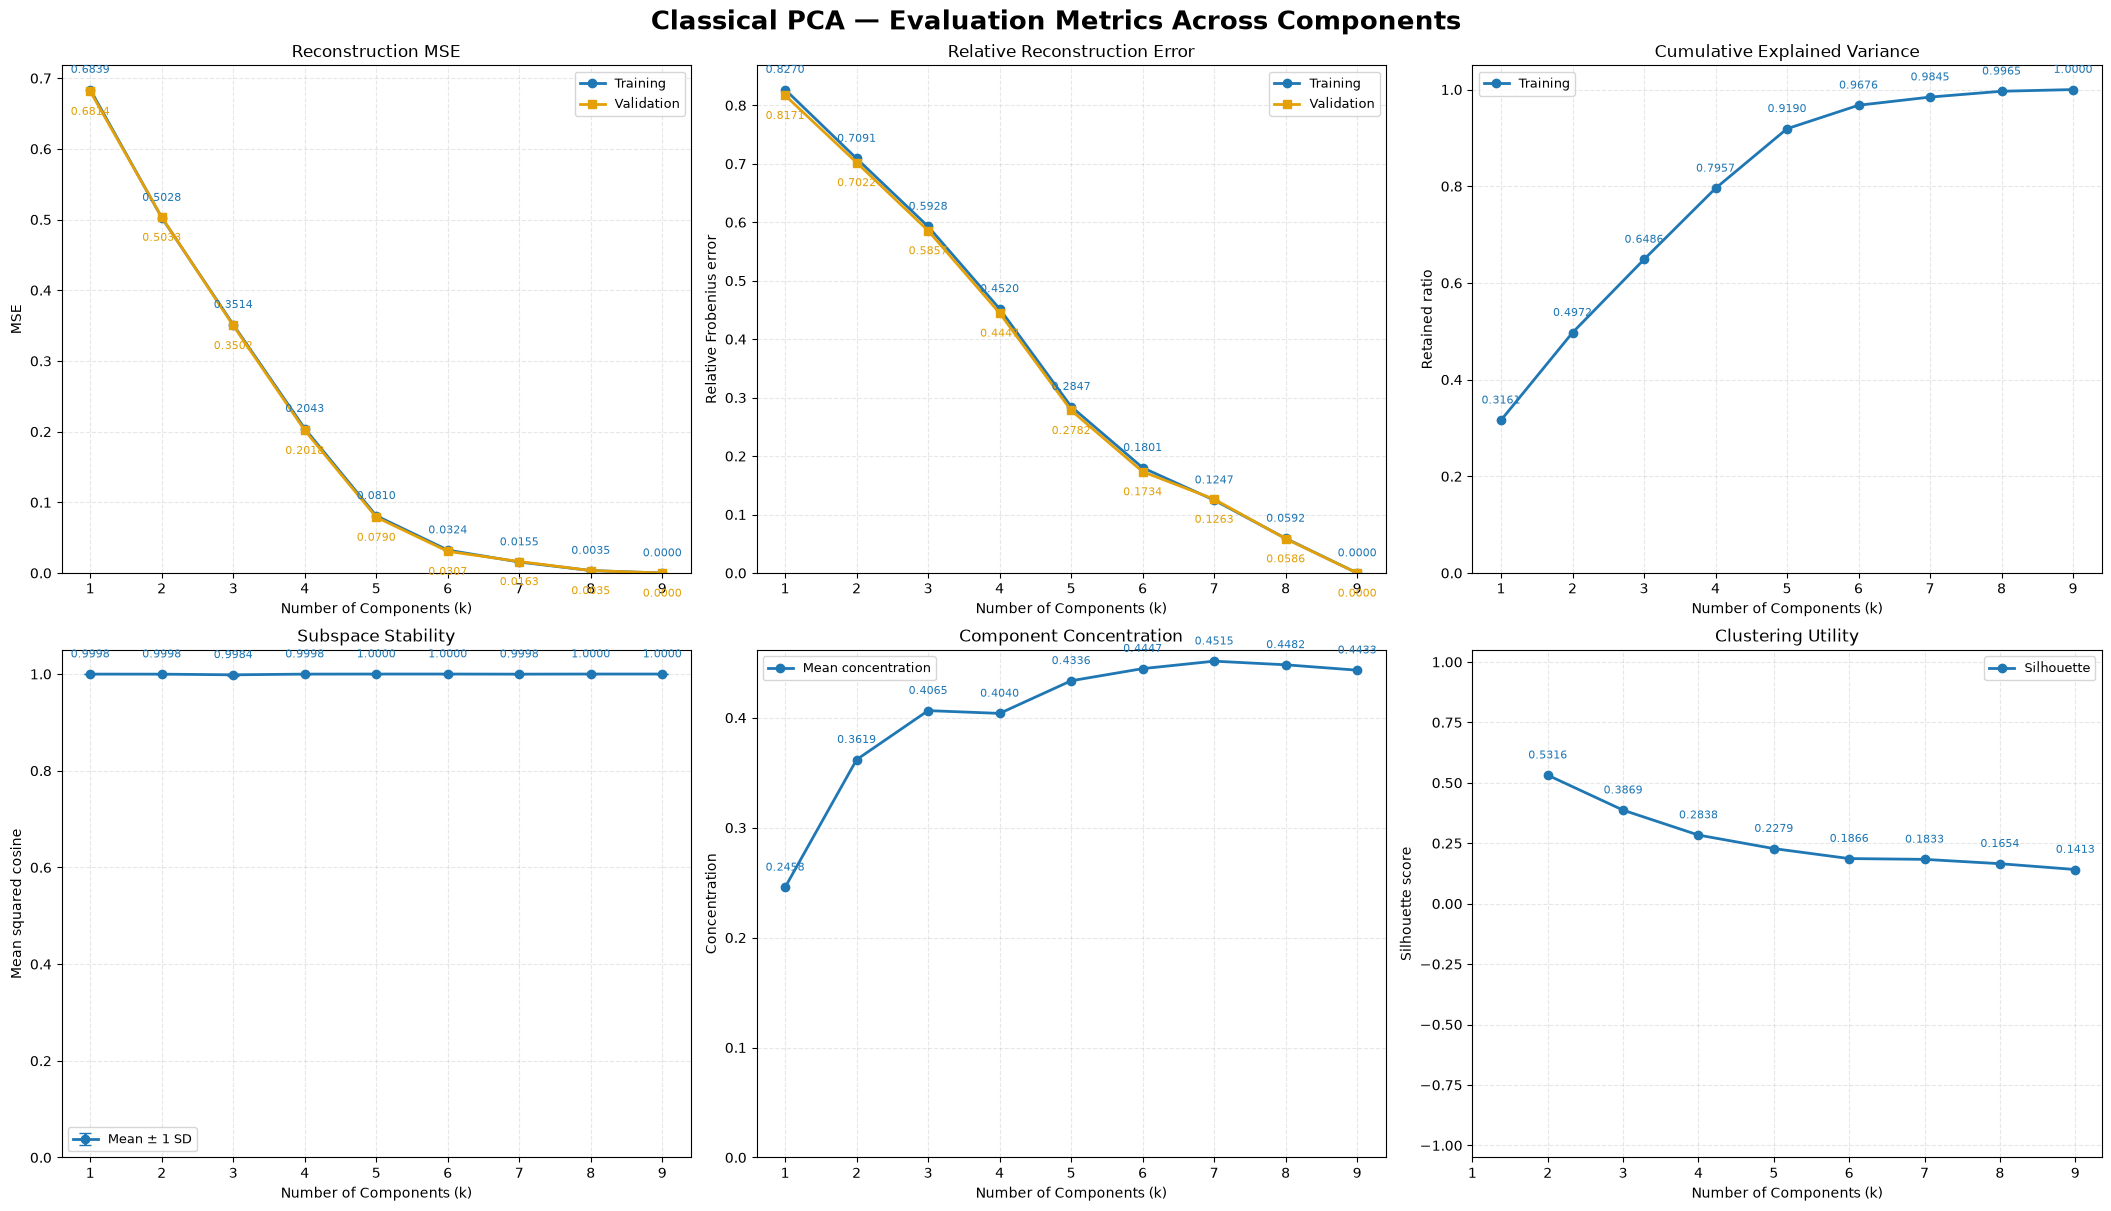

In [91]:
plot_search(pca_search)


**Observations**
-  The subspace stability is almost the same in every component, which means that the geometric space doesn't change much when we use another samples.
- The silhouette decreases when we increment the number of components.
We are going to select $k=5$ because:
- It reduces better the reconstruction error and the relative reconstructione error than $k\text{s}$ that are lower, and also it is a value that helps to reduce the original dimensionality of the data ($p=10$)
- It retains almost the 92% of the explained variance of the data.
- It presents a high value for component concentration in constrast with lower $k\text{s}$
- It presents higher silhouette score than greater numbers of components.



### **4.5 PCA Analysis with 5 components**

In [92]:
pca_analysis = PCAAnalysis(data, k=5).fit()


In [93]:
pca_analysis.latent_frame("train").head()


,PC1,PC2,PC3,PC4,PC5
99963,-0.965746,-3.978939,0.448102,1.097971,0.482907
63538,0.105215,-0.435407,0.391753,-1.019697,-0.591921
6661,-0.252838,0.507697,-0.165234,1.207142,0.343072
93913,-0.266260,-0.475264,0.666033,1.923215,-1.437925
90626,-0.482250,-0.923258,0.262893,1.146375,-1.212370


In [94]:
pca_analysis.loadings.round(4)


,PC1,PC2,PC3,PC4,PC5
Days for shipping (real),0.0025,-0.0176,0.7054,0.0443,0.0104
Days for shipment (scheduled),0.0054,-0.0168,0.7057,0.0398,0.0091
Benefit per order,0.1114,0.6938,0.0136,0.0468,-0.0189
Sales per customer,0.5191,-0.0244,0.0058,-0.2075,0.2409
Order Item Discount,0.4150,-0.0923,-0.0344,0.5014,-0.0426
Order Item Discount Rate,0.0976,-0.0891,-0.0439,0.7549,-0.2412
Order Item Profit Ratio,0.0408,0.7043,0.0132,0.0774,-0.0568
Order Item Quantity,-0.0417,0.0299,-0.0251,0.2395,0.8544
Sales,0.5397,-0.0374,-0.0004,-0.1057,0.2117
Product Price,0.4916,-0.0504,0.0144,-0.2354,-0.3216


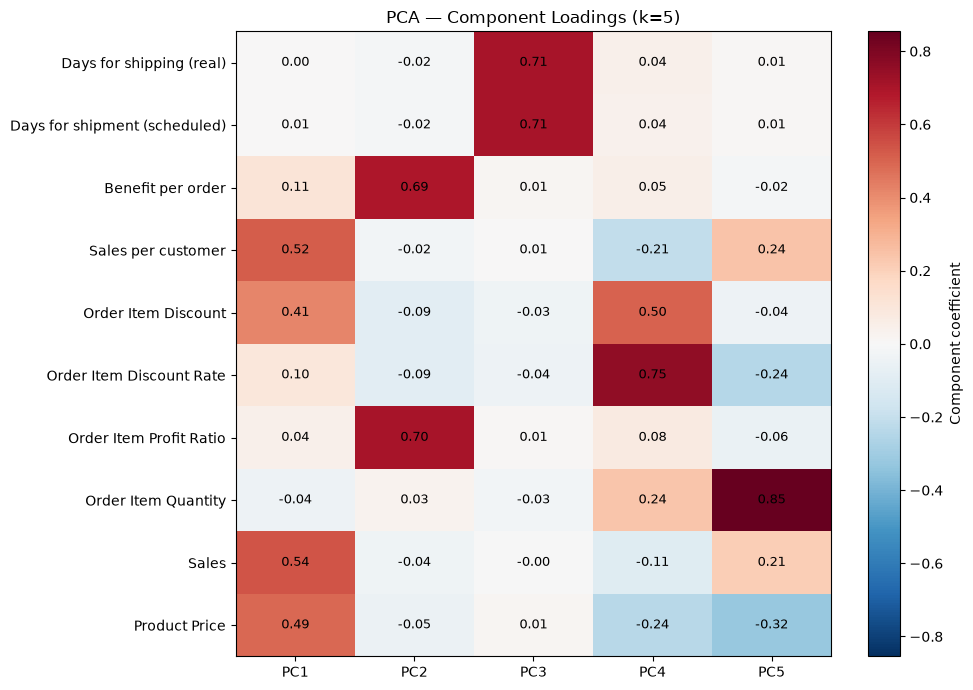

In [95]:
plot_loadings(pca_analysis)


**Observations**
- **Component 1 — High Sales and Discounts:** This component appears to capture positive contributions from Sales per customer, order item discount, sales and product price. It appears to involve products that have an elevated price, greater sales values, and larger absolute discount amounts.

- **Component 2 — Profitability:** This component is dominated by Benefit per order and Order Item Profit Ratio, where we can suggest that this component represents the orders that have high profitability.

- **Component 3 — Shipping Duration:** This component is dominated Days for shipping (real) and Days for shipment (schedule), it appears to describe the orders with longer scheduled and actual shipping durations.

- **Component 4 — Discounts and Relatively Low Sales:** This component captures positive and higher contributions of Order Item Discount Rate and Order Item Discount while small and negative contributions with Sales, Product Price and Sales per costumer. This component could represent the orders that have a high discount, but they get relatively lower sales values to the company.

- **Component 5 - Quantity:** This component has a strong positive contribution with Order Item quantity, a positive but not strong with sales and sales per costumer, but a negative contribution with order item discount rate and product price. This suggest that the component could represent the orders that usually have a low price per product without a high discount, but they have a larger quantities per order, associated with modestly higher sales values.

In [96]:
pca_analysis.variance_summary().round(4)


,Component,Explained Variance Ratio,Cumulative Explained Variance
0,PC1,0.3161,0.3161
1,PC2,0.1811,0.4972
2,PC3,0.1514,0.6486
3,PC4,0.1471,0.7957
4,PC5,0.1233,0.9190


In [97]:
{split: values.shape for split, values in pca_analysis.reconstructions.items()}


{'train': (126363, 10), 'validation': (27078, 10), 'test': (27078, 10)}

### **4.6 MSE Final Test**

In [98]:
pca_analysis.metrics().round(6)


,Reconstruction MSE,Relative Frobenius
train,0.081028,0.284654
validation,0.078985,0.278170
test,0.079776,0.285037


## **5. Probabilistic PCA (PPCA)** 

### **5.1 Notation**

PPCA stands for Probabilistic Principal Component Analysis. It uses almost the same structure we use in PCA:

$$
Z = X_cV_k
$$

Where we could find an approximation of the original matrix with:

$$
\hat{X} = ZV_k^T+\bm{1}\mu
$$

However, PPCA introduces a probabilistic assumption

$$
\boxed{X_c=ZW^\top+E}
$$

where Z is the unobserved random variables and $E$ is a random gaussian noise. Also we assume that

$$
Z_{i,:}^\top\sim\mathcal N(0,I_k)
$$

$$
E_{i,:}^\top\sim\mathcal N(0,\sigma^2I_p)
$$

In this way, because $Z_{i,:}^\top$ and $E_{i,:}^\top$ are Gaussian random variables. Therefore, their lineal combination will be also a Gaussian random variable defined as

$$
\boxed{X_{c,i,:}^\top\sim\mathcal N(0,C)}
$$

and 

$$
\boxed{C=WW^\top+\sigma^2I_p}
$$

where $WW^\top$ is the covariance explained by the $k$ latent variables and $\sigma^2I_p$ is the remaining variance that is assumed equal for every feature direction. Furthermore, $C$ represents our covariance matrix assumed by the probabilistc model.

### **5.2 Applying PPCA with different $k$**

In [99]:
ppca_search = PPCASearch().run(data)
display(ppca_search.results.round(4))


,k,Train MSE,Validation MSE,Train Relative Frobenius,Validation Relative Frobenius,Cumulative Explained Variance,Subspace Stability,Stability SD,Mean Concentration,Silhouette Score,Train Log-Likelihood,Validation Log-Likelihood,Estimated Noise Variance
0,1,0.6839,0.6814,0.8270,0.8171,0.3161,0.9998,0.0002,0.2458,NaN,-13.5293,-13.5497,0.7599
1,2,0.5028,0.5033,0.7091,0.7022,0.4972,0.9998,0.0002,0.3619,0.5316,-13.2041,-13.2365,0.6285
2,3,0.3514,0.3502,0.5928,0.5857,0.6486,0.9984,0.0026,0.4065,0.3869,-12.8570,-12.8791,0.5020
3,4,0.2043,0.2018,0.4520,0.4447,0.7957,0.9998,0.0001,0.4040,0.2838,-12.2299,-12.2322,0.3405
4,5,0.0810,0.0790,0.2847,0.2782,0.9190,1.0000,0.0000,0.4336,0.2279,-11.0172,-10.9909,0.1621
5,6,0.0324,0.0307,0.1801,0.1734,0.9676,1.0000,0.0000,0.4447,0.1866,-10.1817,-10.1068,0.0811
6,7,0.0155,0.0163,0.1247,0.1263,0.9845,0.9998,0.0002,0.4515,0.1833,-9.8770,-9.9070,0.0518
7,8,0.0035,0.0035,0.0592,0.0586,0.9965,1.0000,0.0000,0.4482,0.1654,-9.2148,-9.2050,0.0175
8,9,0.0000,0.0000,0.0000,0.0000,1.0000,1.0000,0.0000,0.4433,0.1413,0.0884,0.1149,0.0000


### **5.3 Metrics Visualization**

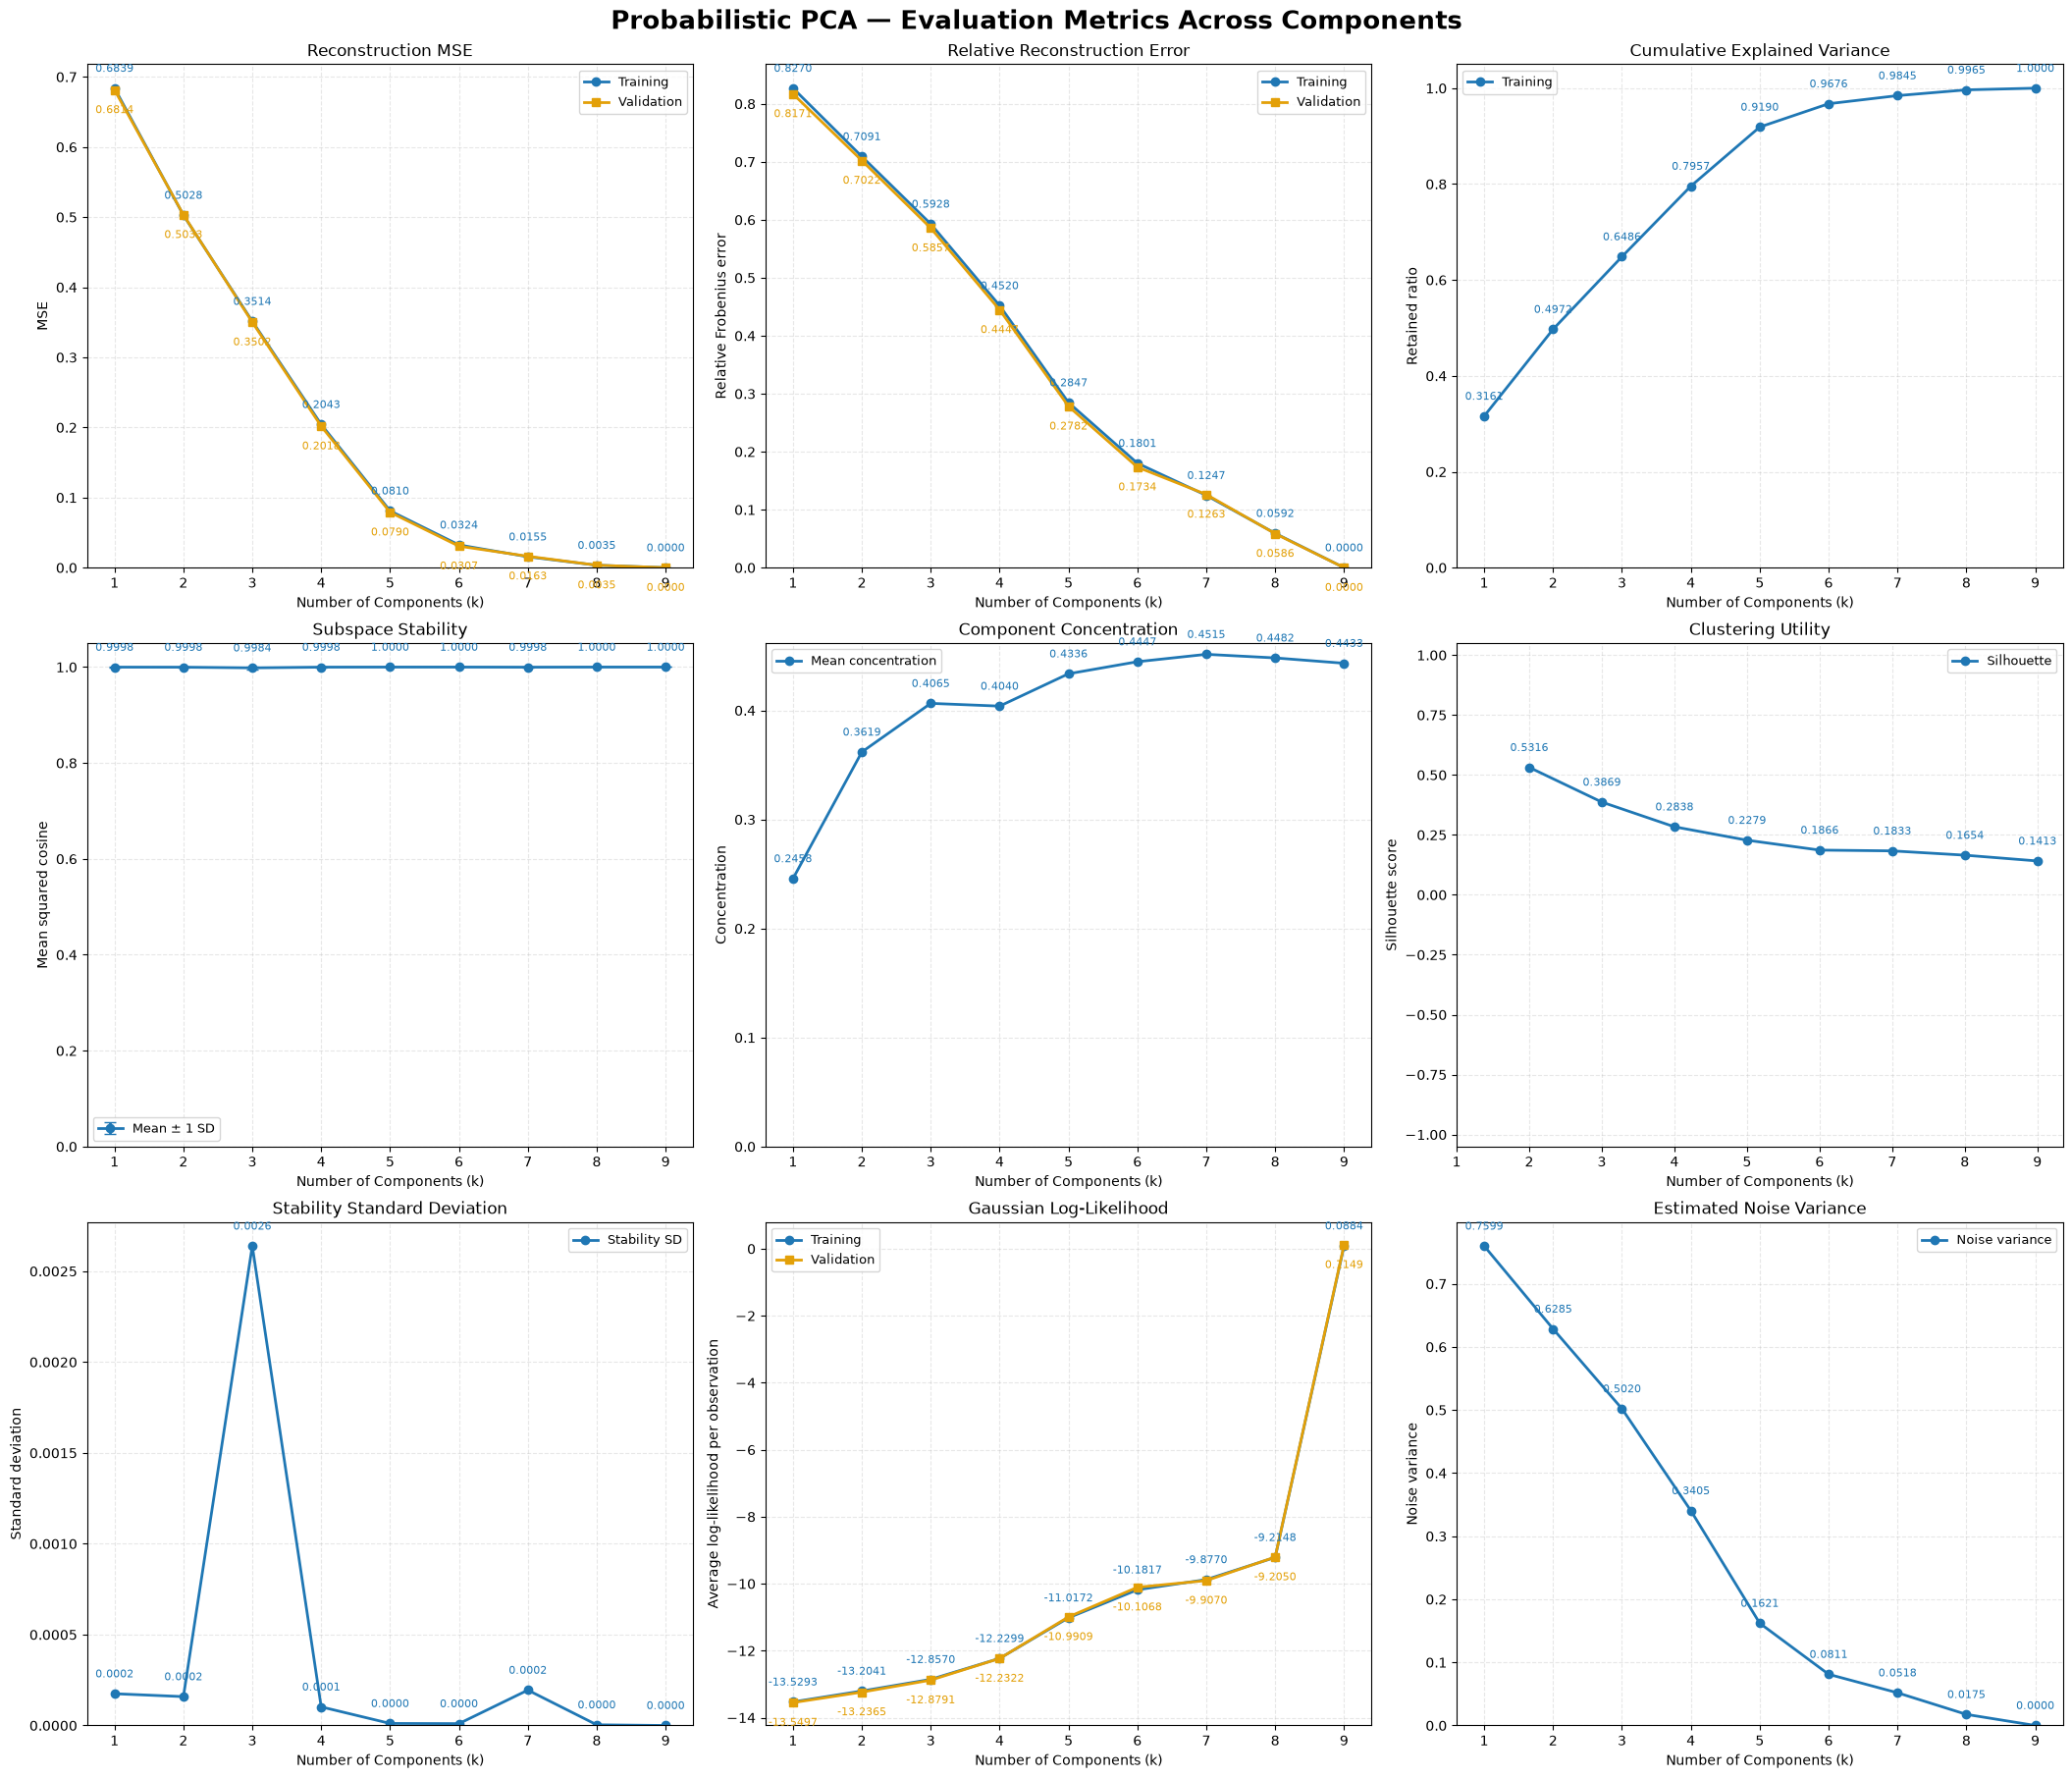

In [100]:
plot_search(ppca_search)


**Observations**
-  The subspace stability standard deviation is near cero in each component, which means that the geometric space doesn't change much when we use another samples.
- The silhouette decreases when we increment the number of components.
We are going to select $k=5$ because:
- It presents a higher validation log-likelihood than lower $k\text{s}$ without sacrificing the reducing dimensionality intention (higher $k\text{s}$)
- It reduces better the reconstruction error and the relative reconstructione error than $k\text{s}$ that are lower, and also it is a value that helps to reduce the original dimensionality of the data ($p=10$).
- It retains almost the 92% of the explained variance of the data.
- It presents a high value for component concentration in constrast with lower $k\text{s}$, whichj means that the retained representation captures a considerable ammount of information in its principal directions.
- It presents higher silhouette score than greater numbers of components.



### **5.4 PPCA Analysis with 5 components**

In [101]:
# PPCAAnalysis builds W and uses posterior latent means for reconstruction.
ppca_analysis = PPCAAnalysis(data, k=5).fit()
print("PPCA loading matrix shape:", ppca_analysis.W.shape)
print("Latent shapes:", {split: values.shape for split, values in ppca_analysis.latent.items()})
print("Estimated noise variance:", ppca_analysis.model.noise_variance_)


PPCA loading matrix shape: (10, 5)
Latent shapes: {'train': (126363, 5), 'validation': (27078, 5), 'test': (27078, 5)}
Estimated noise variance: 0.16205696973765038


,Latent 1,Latent 2,Latent 3,Latent 4,Latent 5
Days for shipping (real),0.0043,-0.0226,0.8203,0.0506,0.0108
Days for shipment (scheduled),0.0094,-0.0215,0.8206,0.0456,0.0094
Benefit per order,0.1928,0.8910,0.0158,0.0535,-0.0195
Sales per customer,0.8989,-0.0313,0.0067,-0.2374,0.2492
Order Item Discount,0.7187,-0.1185,-0.0400,0.5737,-0.0441
Order Item Discount Rate,0.1690,-0.1145,-0.0511,0.8637,-0.2496
Order Item Profit Ratio,0.0706,0.9045,0.0153,0.0886,-0.0588
Order Item Quantity,-0.0722,0.0384,-0.0292,0.2740,0.8840
Sales,0.9346,-0.0480,-0.0005,-0.1209,0.2190
Product Price,0.8514,-0.0647,0.0168,-0.2693,-0.3327


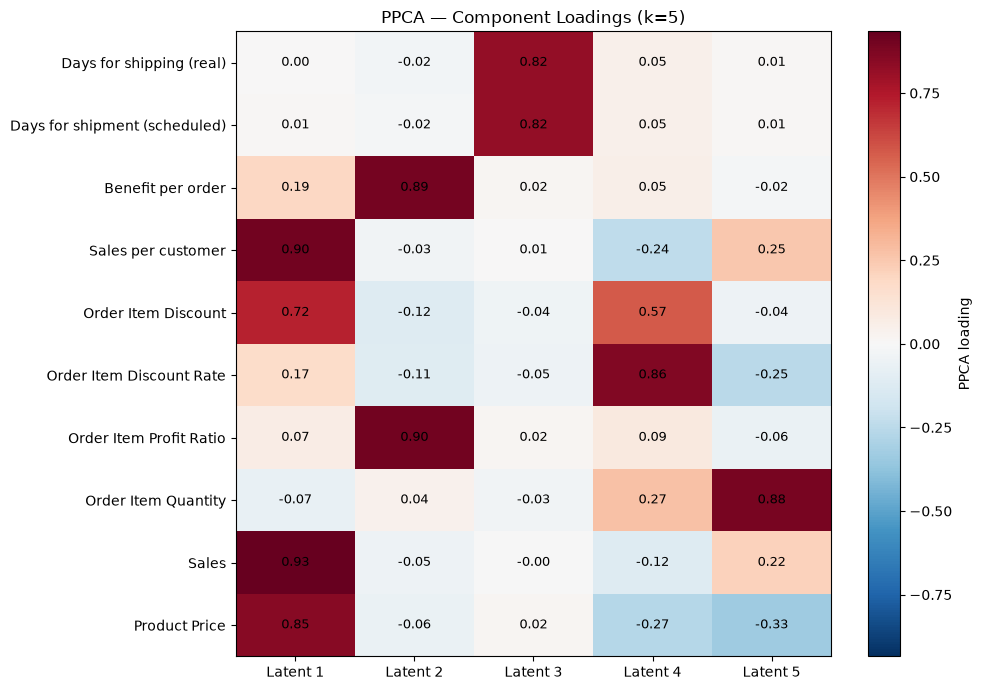

In [102]:
display(ppca_analysis.loadings.round(4))
plot_loadings(ppca_analysis)


**Observations**

- **Component 1 — High Sales and Product Price:** This component appears to capture strong positive contributions from Sales, Sales per customer and product price. It appears to capture a general pattern with high sales and products that have a high price.

- **Component 2 — Profitability :** This component has strong positive contributions from Benefit per order and Order Item Profit Ratio, which indicates that this component captures variation associated with order profitability.

- **Component 3 — Delivery Time:** This component is dominated strongly by positive contributions of Days for shipping (real) and Days for shipment (schedule). The component could represent the orders that have a long delivery time.

- **Component 4 — Discounts and Low Sales** This component involves positive contributions from Order discount rate (strong), order item discount  (strong) and order item quantity (moderate), while it has negative contributions from product price and sales per customer (weak-moderate). This component could represent the orders that included a high discount rate and item discount, but lower sales, which could indicate a lower transaction value

- **Component 5 — Quantity and Low Product Price:** Order Item quantity dominates the component, sales and sales per customer have a weak-moderate contribution while Product price and Order item discount rate have moderate negative contributions. This component could capture a general pattern of orders with high number of items and low product prices.


### **5.5 MSE Final Test**

In [103]:
display(ppca_analysis.metrics().round(6))
display(ppca_analysis.variance_summary().round(4))
print("Estimated noise variance:", ppca_analysis.model.noise_variance_)


,Reconstruction MSE,Relative Frobenius,Average Log-Likelihood
train,0.088959,0.298260,-11.017188
validation,0.086981,0.291911,-10.990890
test,0.087599,0.298687,-10.939134


,Component,Explained Variance Ratio,Cumulative Explained Variance
0,Latent 1,0.3161,0.3161
1,Latent 2,0.1811,0.4972
2,Latent 3,0.1514,0.6486
3,Latent 4,0.1471,0.7957
4,Latent 5,0.1233,0.9190


Estimated noise variance: 0.16205696973765038


## **6. Final Comparison**

In [104]:
comparison = ReductionComparison(svd_analysis, pca_analysis, ppca_analysis).run()
comparison.results.round(4)


,Model,Components,Test MSE,Test RMSE,Relative Frobenius,Retained Energy,Explained Variance,Silhouette,Avg Log-Likelihood
0,Truncated SVD,5,0.0883,0.2971,0.1714,0.9706,NaN,0.2524,NaN
1,Classical PCA,5,0.0798,0.2824,0.2850,NaN,0.919,0.2530,NaN
2,PPCA,5,0.0876,0.2960,0.2987,NaN,0.919,0.2373,-10.9391


**Observations**
- All the three methods implemented help to reduce the dimensionality by a 50% (10 features to 5 components). 
- The reported reconstruction errors MSE and RMSE tend to be better in PCA in contrast with Truncated SVD and PPCA. 
- The relative Frobenius error benefits Truncated SVD while PCA and PPCA present higher values. This indicates that Truncated SVD have a smaller relative reconstruction error within its own scaled representation.
- PCA got the highest silhouette score, which means that is better separating k-means clusters in its reduced space.
- PCA and PPCA have the same explained variance because they identify the same principal subspace.

In this way, the select PCA as the appropiated technique for the excercise because it balances reconstruction quality with information preservation and clustering separation. It reaches 92% of the original standardized variance and reduces the dimensionality by a 50%

**Limitations**


There exist some limitations of PCA with the data, that can sum in:
- Linear relationships: PCA identifies linear combinations of the original variables, so it could fail capturing non-linear relationships between some features.
- Sensitivity to outliers: The covariance matrix can be influenced by extreme values like long delivery times, expensive items, among others.
- Information Loss: We reduced the space in a 50% (10 features to 5 components), which makes us to discard some of the data variability. In this case, we retained the 92% of the variability, which means that we lost an 8% of it.
- Interpretability: There are some components that have strong contributions of many variables with different signs, which can difficult the interpretation of the components indepently.
- Scaling Sensitivity: The results can change if we use different scaling methods, because PCA is affected by the scale of the input variables.
- Variances doesn't guarentee useful separation: We got that PCA had the better Silhoutte score, but PCA doesn't guarantee an optimal separation group performance, it just maximizes the variance.
- PCA doesn't contemplate explicit uncertainty: Unlike PPCA, PCA gives deterministic projections withouth a probabilisitc noise model, which means that there is a lack of estimated uncertainty in the latent variables.